In [2]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
data = load_breast_cancer()
X = data.data
y = data.target
print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']


In [4]:
#Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42,
stratify=y)
#Create and train the Decision Tree model
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
#Make predictions
y_pred = model.predict(X_test)
#Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))


Accuracy: 0.9385964912280702

Confusion Matrix:
[[38  4]
 [ 3 69]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



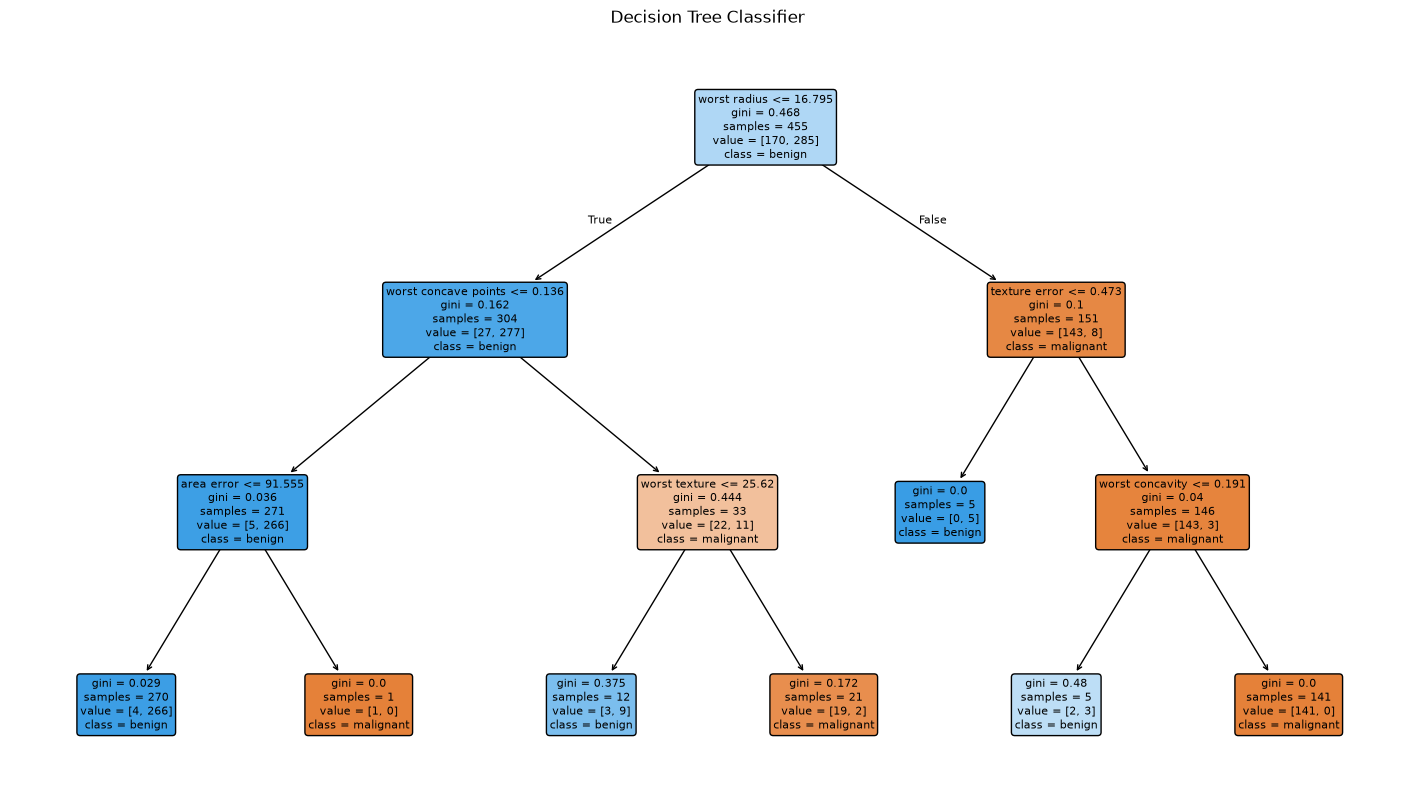

In [6]:
# Visualize the Decision tree
plt.figure(figsize=(18, 10))
plot_tree(model,feature_names=data.feature_names,class_names=data.target_names,
          filled=True,rounded=True,fontsize=8)
plt.title("Decision Tree Classifier")
plt.show()

In [11]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
data = load_breast_cancer()
X = data.data
y = data.target
print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']


In [9]:
#Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42,
stratify=y)
#Create and train the Random Forest model
model = RandomForestClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
#Make predictions
y_pred = model.predict(X_test)
#Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))


Accuracy: 0.956140350877193

Confusion Matrix:
[[39  3]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.93      0.94        42
      benign       0.96      0.97      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114



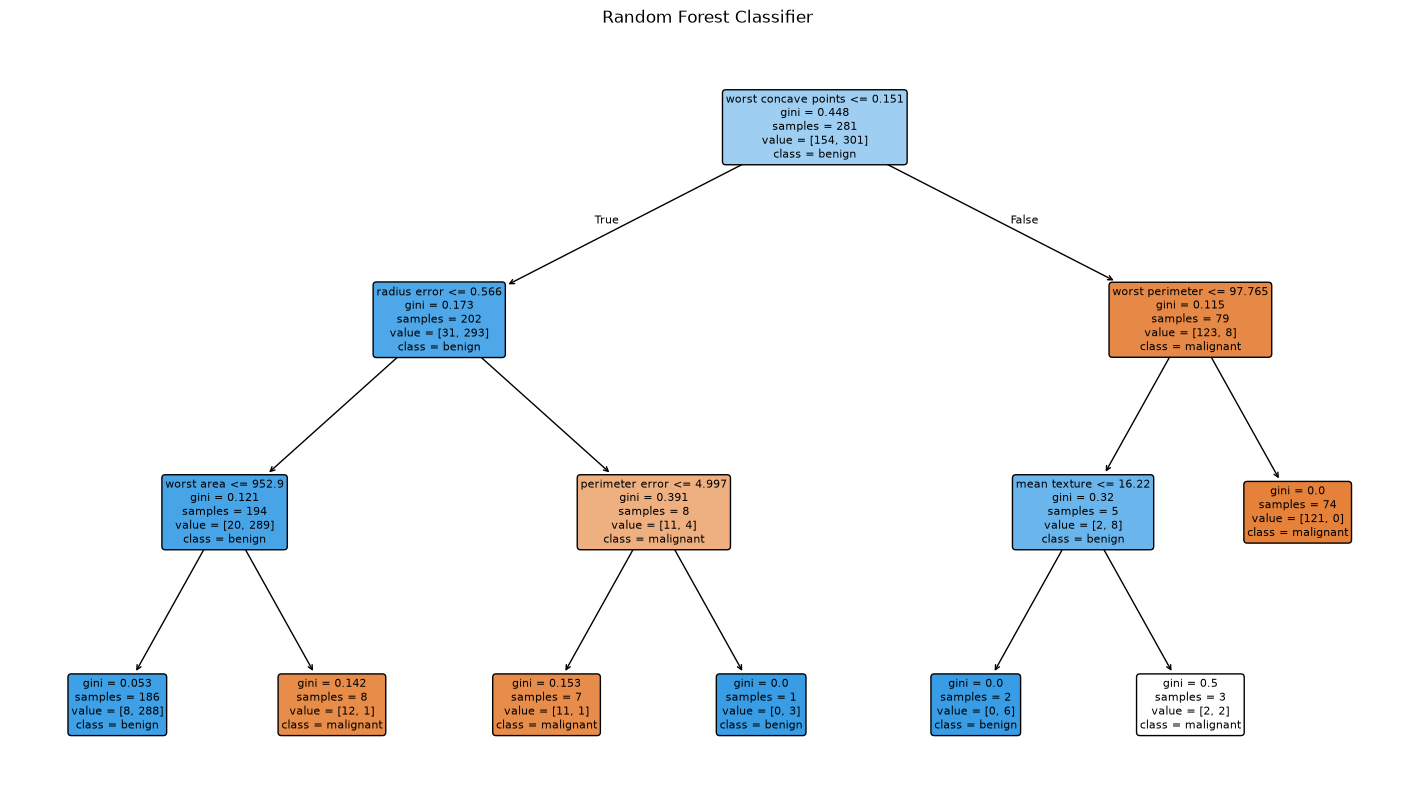

In [14]:
# Visualize the Random Forest
plt.figure(figsize=(18, 10))
plot_tree(model.estimators_[0],feature_names=data.feature_names,class_names=data.target_names,
          filled=True,rounded=True,fontsize=8)
plt.title("Random Forest Classifier")
plt.show()

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
data = load_breast_cancer()
X = data.data
y = data.target
print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']


In [17]:
#Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42,
stratify=y)
#Create and train the SVM model
model = SVC(C=1.0, random_state=42)
model.fit(X_train, y_train)
#Make predictions
y_pred = model.predict(X_test)
#Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))


Accuracy: 0.9298245614035088

Confusion Matrix:
[[36  6]
 [ 2 70]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.95      0.86      0.90        42
      benign       0.92      0.97      0.95        72

    accuracy                           0.93       114
   macro avg       0.93      0.91      0.92       114
weighted avg       0.93      0.93      0.93       114



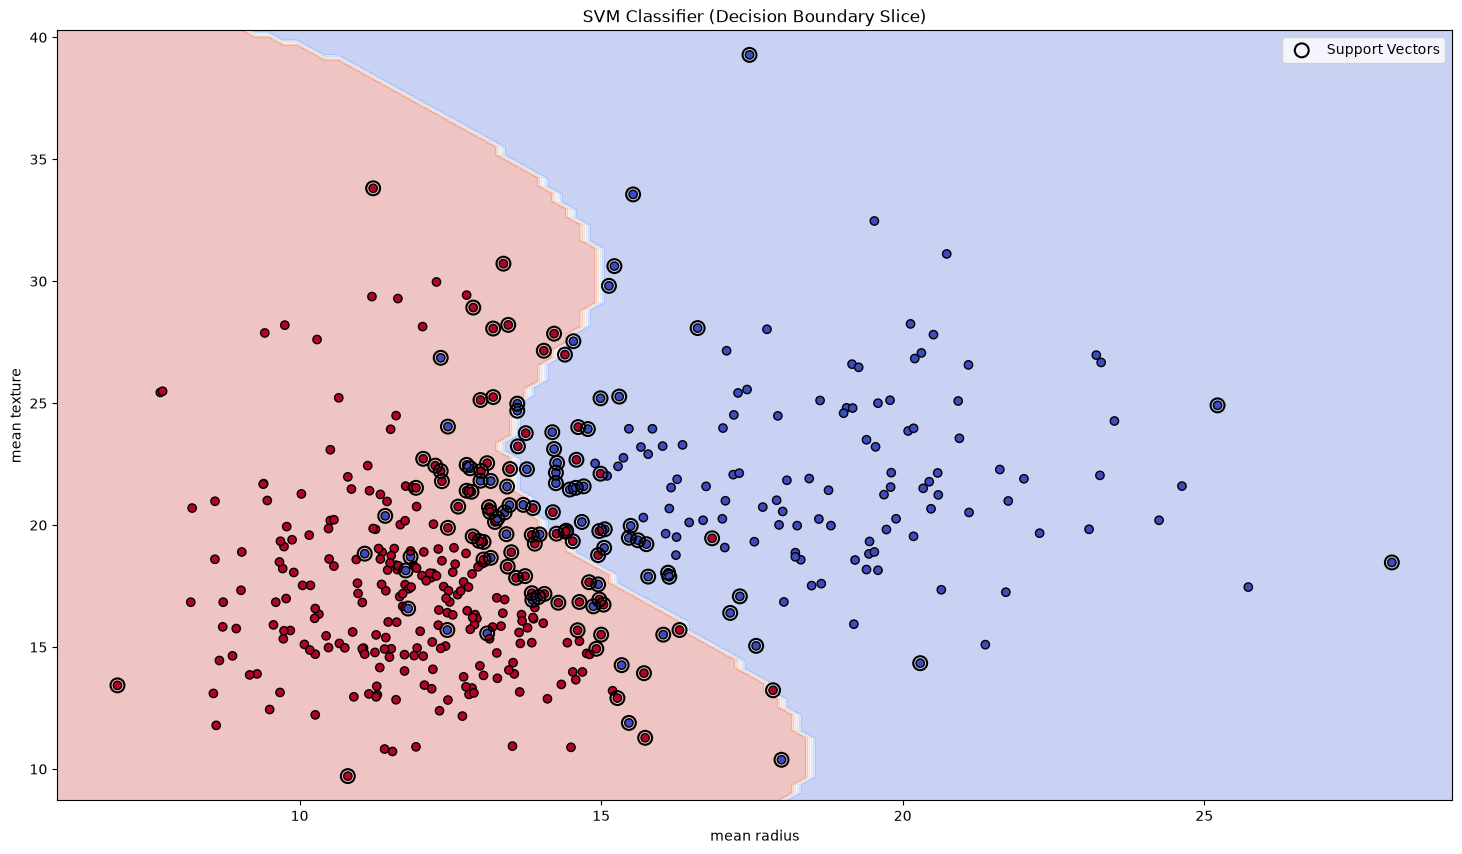

In [24]:
# --- Slicing the data for a 2D Visualization ---
# We take the first two features to display a 2D slice of the boundary
X_train_2d = X_train[:, :2]
X_test_2d = X_test[:, :2]

# Train a fast visualization model on just these 2 features
vis_model = SVC(C=1.0, random_state=42)
vis_model.fit(X_train_2d, y_train)

# --- Visualize the SVM ---
plt.figure(figsize=(18, 10))
ax = plt.gca()

# Draw the SVM decision regions
DecisionBoundaryDisplay.from_estimator(
    vis_model,
    X_train_2d,
    response_method="predict",
    cmap=plt.cm.coolwarm,
    alpha=0.3,
    ax=ax,
)

# Scatter plot the actual training points
ax.scatter(
    X_train_2d[:, 0],
    X_train_2d[:, 1],
    c=y_train,
    cmap=plt.cm.coolwarm,
    edgecolors="k",
)

# Highlight and circle the support vectors
ax.scatter(
    vis_model.support_vectors_[:, 0],
    vis_model.support_vectors_[:, 1],
    s=100,
    facecolors="none",
    edgecolors="k",
    linewidths=1.5,
    label="Support Vectors",
)

plt.title("SVM Classifier (Decision Boundary Slice)")
plt.xlabel(data.feature_names[0])
plt.ylabel(data.feature_names[1])
plt.legend()
plt.show()

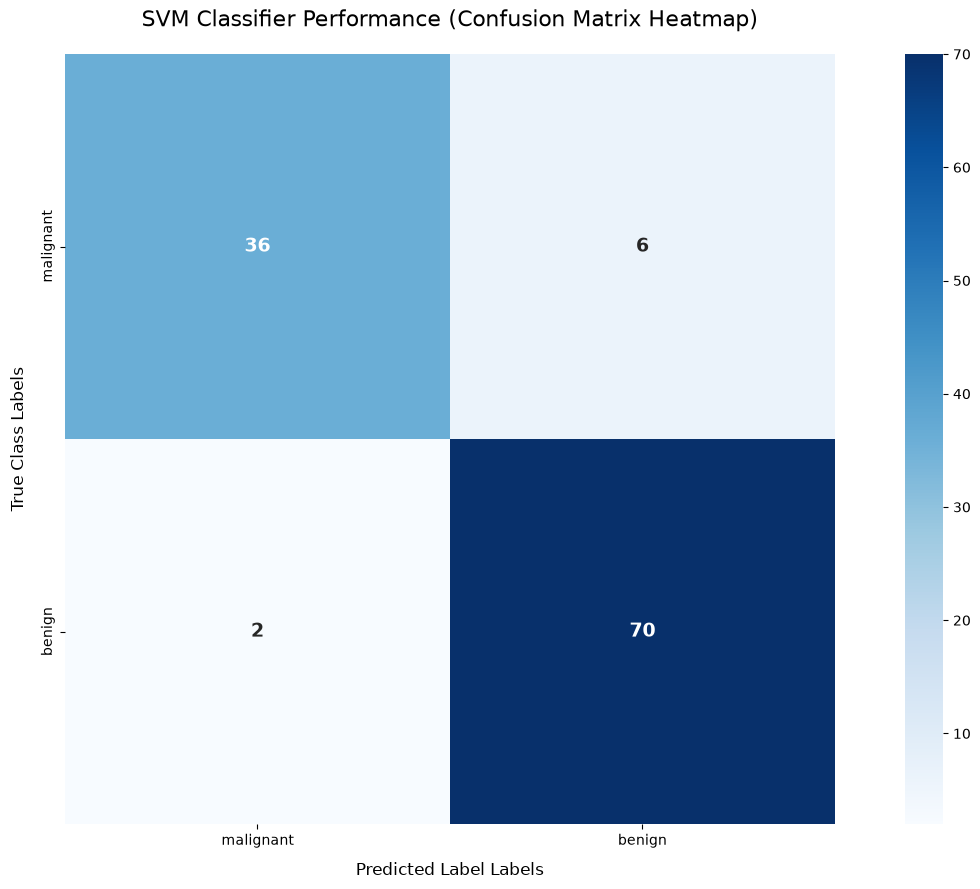

In [29]:
# --- Visualize the SVM via Confusion Matrix Heatmap ---
plt.figure(figsize=(18, 10))

# 1. Compute your numerical confusion matrix values
cm = confusion_matrix(y_test, y_pred)

# 2. Draw the colored box-grid heatmap
sns.heatmap(
    cm,
    annot=True,  # Displays numbers directly inside the blocks
    fmt="d",  # Formats numbers as standard integers
    cmap="Blues",  # Use color shade variation to indicate frequency
    xticklabels=data.target_names,
    yticklabels=data.target_names,
    square=True,  # Forces each block to be a perfect square box
    annot_kws={"size": 14, "weight": "bold"},  # Text style inside boxes
    cbar=True,  # Shows color rating bar on the side
)

# 3. Apply labels and presentation formatting
plt.title("SVM Classifier Performance (Confusion Matrix Heatmap)", fontsize=16, pad=20)
plt.xlabel("Predicted Label Labels", fontsize=12, labelpad=10)
plt.ylabel("True Class Labels", fontsize=12, labelpad=10)

plt.show()

In [30]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
data = load_breast_cancer()
X = data.data
y = data.target
print("Dataset shape:", X.shape)
print("Target classes:", data.target_names)

Dataset shape: (569, 30)
Target classes: ['malignant' 'benign']


In [31]:
#Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42,
stratify=y)
#Create and train the Decision Tree model
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
#Make predictions
y_pred = model.predict(X_test)
#Evaluate the model
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=data.target_names))


Accuracy: 0.9385964912280702

Confusion Matrix:
[[38  4]
 [ 3 69]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.93      0.90      0.92        42
      benign       0.95      0.96      0.95        72

    accuracy                           0.94       114
   macro avg       0.94      0.93      0.93       114
weighted avg       0.94      0.94      0.94       114



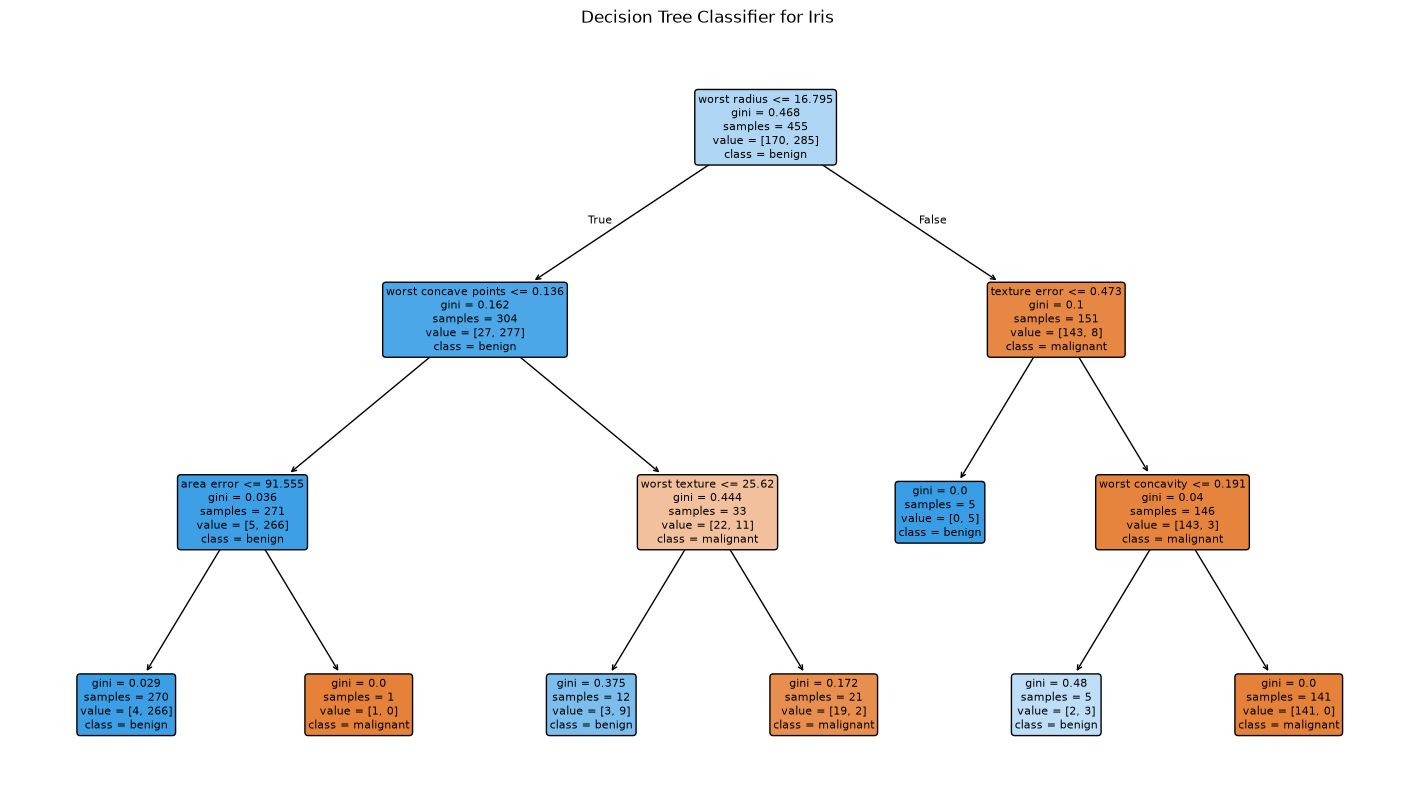

In [33]:
# Visualize the Decision tree
plt.figure(figsize=(18, 10))
plot_tree(model,feature_names=data.feature_names,class_names=data.target_names,
          filled=True,rounded=True,fontsize=8)
plt.title("Decision Tree Classifier for Iris")
plt.show()